In [2]:
import os
from copy import copy
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns

import numpy as np
import pandas as pd
import umap
import pickle
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
import matplotlib as mpl

import scanpy as sc
import anndata
import scanpy.external as sce
from csspy import csspy

# from scarches.models.scpoli import scPoli


In [3]:
project_dir = '/home/xuquan/projects/pdac'
sc.settings.figdir = f'{project_dir}/figures/'
fig_dir = f'{project_dir}/figures/'

gns = copy(mpl.cm.Blues)
gns.set_under("lightgray")

plate_level_all0 = pd.read_csv(f"{project_dir}/db/pdac_color.txt",
                               sep='\t', header=None, index_col=0)
plate_level_all = plate_level_all0.to_dict()[1]
plate_level_all['nan'] = 'lightgray'


mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(facecolor=(0, 0, 0, 0), dpi=50, dpi_save=600)

sns.set_style({'axes.grid': False})


/tmp/ipykernel_2110935/2362611203.py:16: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(facecolor=(0, 0, 0, 0), dpi=50, dpi_save=600)


In [4]:

w_res_cancer = pd.read_excel('/home/xuquan/projects/pdac/atlas_res/pdac_cancer_degenes_wc_20250509.xlsx', 
                             sheet_name='cancer', index_col=0)

w_res_caf = pd.read_excel('/home/xuquan/projects/pdac/atlas_res/pdac_caf_degenes_wc_20250509.xlsx', 
                             sheet_name='caf', index_col=0)


In [5]:
w_res_cancer['cancer'] = w_res_cancer.logfc * w_res_cancer['-log10p']
w_res_caf['caf'] = w_res_caf.logfc * w_res_caf['-log10p']

merged_degenes = pd.merge(w_res_cancer, w_res_caf, 
                          left_index=True, right_index=True, how='outer')
merged_degenes = merged_degenes.fillna(0)

cutoff_score = 1

merged_degenes['condition']='nan'
merged_degenes.loc[(merged_degenes.cancer>cutoff_score)&(merged_degenes.caf<cutoff_score), 'condition'] = 'Cancer'
merged_degenes.loc[(merged_degenes.caf>cutoff_score)&(merged_degenes.cancer<cutoff_score), 'condition'] = 'CAF'
merged_degenes.loc[(merged_degenes.cancer>cutoff_score)&(merged_degenes.caf>cutoff_score), 'condition'] = 'PDAC'

caf_genes = merged_degenes[merged_degenes.condition.isin(['CAF','PDAC'])].index.tolist()
caf_weights = merged_degenes[merged_degenes.condition.isin(['CAF','PDAC'])].caf.tolist()


merged_degenes.head()


,logfc_x,pvalue_x,pect_x,-log10p_x,cancer,logfc_y,pvalue_y,pect_y,-log10p_y,caf,condition
A1BG,-0.014031,3.383692e-12,0.236181,11.470609,-0.160940,-0.059111,1.689856e-07,0.324742,6.772150,-0.400306,nan
A1BG-AS1,0.000000,0.000000e+00,0.000000,0.000000,0.000000,-0.011236,5.897628e-06,0.288660,5.229323,-0.058757,nan
A1CF,-0.001219,5.155710e-01,0.482412,0.287712,-0.000351,0.000000,0.000000e+00,0.000000,0.000000,0.000000,nan
A2M,-0.207814,1.539911e-23,0.185930,22.812504,-4.740754,-1.114781,6.229137e-30,0.082474,29.205572,-32.557826,nan
A2M-AS1,-0.011668,5.547347e-20,0.216080,19.255915,-0.224674,0.003220,1.258129e-02,0.515464,1.900275,0.006118,nan


In [10]:

cancer_genes = merged_degenes[merged_degenes.condition.isin(['Cancer','PDAC'])].index.tolist()
cancer_weights = merged_degenes[merged_degenes.condition.isin(['Cancer','PDAC'])].cancer.tolist()


In [13]:
def weighted_score_genes(adata, gene_list, weights, score_name="weighted_gene_score", use_raw=True):
    """
    Mimic scanpy.tl.score_genes to calculate a weighted gene score using z-scored expression.

    Parameters:
        adata : AnnData
            Annotated data matrix in Scanpy.
        gene_list : list
            List of gene names to calculate the weighted score for.
        weights : list
            Paired list of weights corresponding to each gene in the gene_list.
        score_name : str
            The column name to store the result in `adata.obs`.
        use_raw : bool
            If True, use `adata.raw` as the source of expression data.
            If False, use `adata.X` (main AnnData matrix).

    Returns:
        None
            Adds the weighted z-score as a new column in `adata.obs`.
    """
    # Determine data source
    if use_raw:
        if adata.raw is None:
            raise ValueError("adata.raw is not set. Set `adata.raw` or use `use_raw=False`.")
        data_source = adata.raw
    else:
        data_source = adata
    
    # Ensure the gene list and weights are paired
    if len(gene_list) != len(weights):
        raise ValueError("The gene list and weight list must have the same length.")
    
    # Filter the gene list to include only those present in the dataset
    valid_pairs = [(gene, weight) for gene, weight in zip(gene_list, weights) if gene in data_source.var_names]
    if len(valid_pairs) == 0:
        raise ValueError("None of the genes in the gene_list are present in the dataset.")

    # Extract valid genes and weights
    valid_genes, valid_weights = zip(*valid_pairs)

    # Extract expression matrix for valid genes (n_cells x n_genes)
    gene_expr = data_source[:, valid_genes].X
    if not isinstance(gene_expr, np.ndarray):  # Convert sparse to dense if necessary
        gene_expr = gene_expr.toarray()

    # Perform z-score normalization for each gene across cells
    gene_expr_zscore = (gene_expr - np.mean(gene_expr, axis=0)) / np.std(gene_expr, axis=0)
    
    valid_weights = np.array(valid_weights) / np.sum(valid_weights)

    # Compute the weighted gene score as a weighted sum of the z-scores
    weighted_scores = np.dot(gene_expr_zscore, valid_weights)

    # Store the result in adata.obs
    adata.obs[score_name] = weighted_scores
    
    


In [13]:
adata = sc.read_h5ad(f'{project_dir}/Ryo_Organoid/caf_all.h5ad')


In [28]:
adata.raw = adata
sc.pp.highly_variable_genes(adata, n_top_genes=2000, batch_key='sample_id')
adata = adata[:, adata.var['highly_variable']].copy()
sc.tl.pca(adata)
sc.pp.neighbors(adata)
adata = csspy.css(adata, cor_method='spearman', resolution=2)
adata = csspy.umap(adata)
sc.tl.leiden(adata, resolution=0.2)


/home/xuquan/miniconda3/envs/scpy/lib/python3.14/site-packages/csspy/csspy.py:77: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, resolution=resolution)
/tmp/ipykernel_225670/4075083557.py:8: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata, re

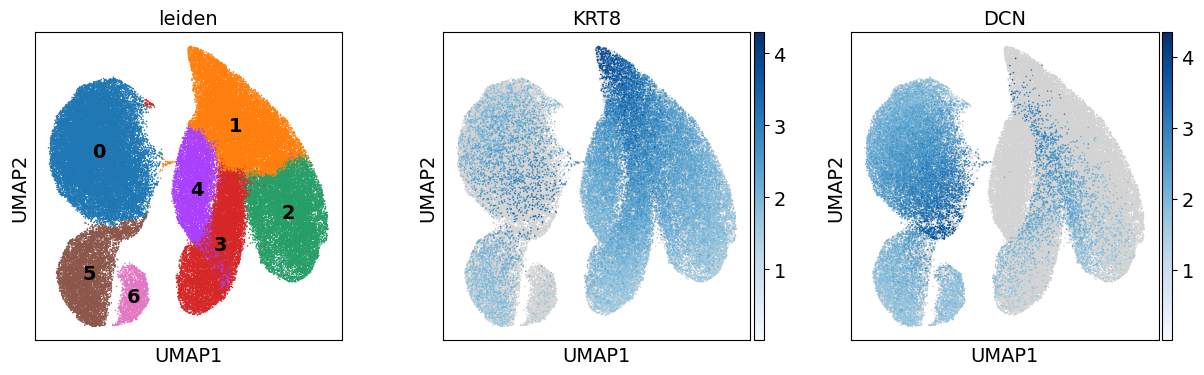

In [30]:
sc.pl.umap(adata, color=['leiden','KRT8','DCN'], legend_loc='on data', 
           color_map=gns, size=5, vmin=0.01)

### Cancer

In [32]:
adata_cancer = adata[adata.obs.leiden.isin(['1','2','3','4'])]
adata_cancer.obs['celltype'] = 'cancer'

adata_cancer = adata_cancer.raw.to_adata()
sc.pp.highly_variable_genes(adata_cancer, n_top_genes=2000, batch_key='sample_id')
adata_cancer.raw = adata_cancer
adata_cancer = adata_cancer[:, adata_cancer.var['highly_variable']].copy()
sc.pp.scale(adata_cancer, max_value=10)
sc.tl.pca(adata_cancer)


/tmp/ipykernel_225670/2891069512.py:2: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata_cancer.obs['celltype'] = 'cancer'
/home/xuquan/miniconda3/envs/scpy/lib/python3.14/functools.py:982: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


In [26]:
# adata_cancer = csspy.css(adata_cancer, cor_method='spearman', resolution=2)
# adata_cancer = csspy.umap(adata_cancer)
sc.tl.leiden(adata_cancer, resolution=0.5)


/tmp/ipykernel_257483/1254026488.py:3: FutureWarning: The `igraph` implementation of leiden clustering is *orders of magnitude faster*. Set the flavor argument to (and install if needed) 'igraph' to use it.
In the future, the default backend for leiden will be igraph instead of leidenalg. To achieve the future defaults please pass: `flavor='igraph'` and `n_iterations=2`. `directed` must also be `False` to work with igraph’s implementation.
  sc.tl.leiden(adata_cancer, resolution=0.5)


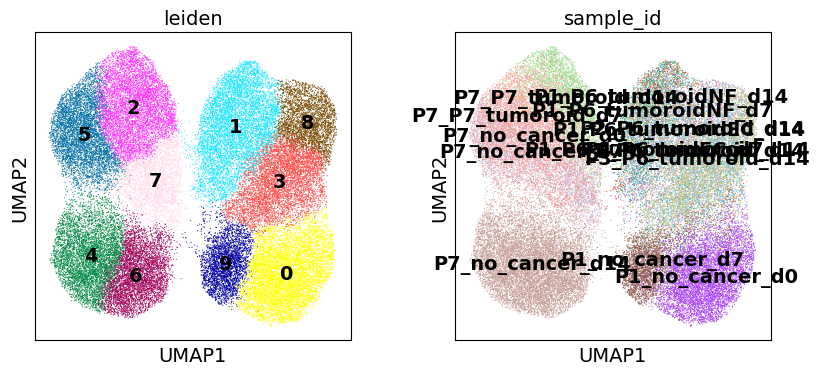

In [27]:
sc.pl.umap(adata_cancer, color=['leiden','sample_id'],
                                legend_loc='on data')


In [7]:
adata_cancer = sc.read_h5ad(f'{project_dir}/Ryo_Organoid/cancer_all_css_new.h5ad')


In [4]:
# adata_cancer = sc.read_h5ad(f'{project_dir}/Ryo_Organoid/cancer_all_css_new.h5ad')


In [30]:
adata_cancer.obs['leiden_m'] = adata_cancer.obs.leiden.map({
    '0':'C4',
    '1':'C7',
    '2':'C3',
    '3':'C6',
    '4':'C1',
    '5':'C2',
    '6':'C1',
    '7':'C2',
    '8':'C8',
    '9':'C5'
})

adata_cancer.obs['leiden_m'] = adata_cancer.obs.leiden.map({
    '0':'C1',
    '1':'C9',
    '2':'C5',
    '3':'C7',
    '4':'C6',
    '5':'C3',
    '6':'C6',
    '7':'C4',
    '8':'C8',
    '9':'C2'
})

In [17]:
adata = adata.raw.to_adata()
adata2 = adata[adata_cancer.obs.index]
adata2.obs=adata_cancer.obs
adata2.obsm['X_umap'] = adata_cancer.obsm['X_umap']


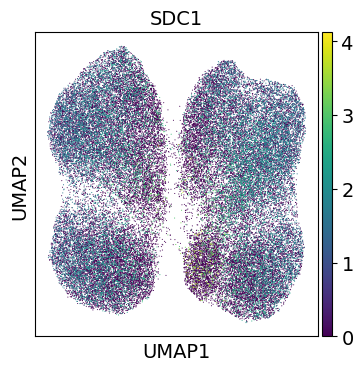

In [33]:
sc.pl.umap(adata2, color='SDC1')

/tmp/ipykernel_606354/1171888458.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(


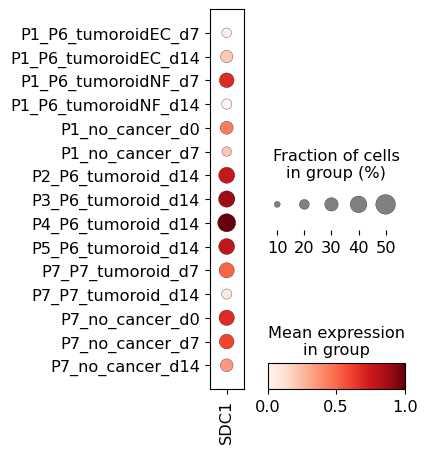

In [36]:

sc.pl.dotplot(
    adata2, 
    var_names=['SDC1'], 
    groupby='sample_id', 
    standard_scale='var',
    figsize=(2.5,5),
#     swap_axes=True,
    save='SDC1_in_sc2.pdf'
)


/tmp/ipykernel_257483/2985397331.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(adata_cancer, color=['leiden_m', 'Timepoint','celltype', 'sample_id'],


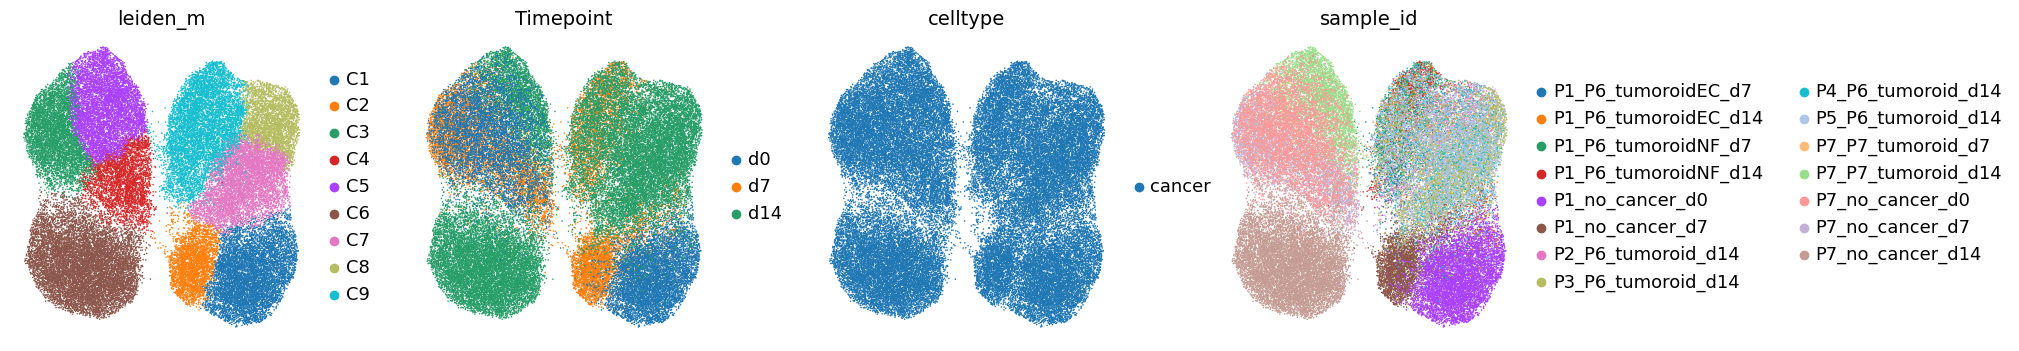

/tmp/ipykernel_257483/2985397331.py:4: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(adata_cancer, color=['leiden_m'],


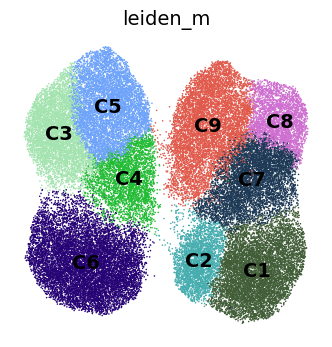

In [31]:


sc.pl.umap(adata_cancer, color=['leiden_m', 'Timepoint','celltype', 'sample_id'], 
           color_map=gns, size=5, vmin=0.01, frameon=False, save='cancer_meta.pdf')

sc.pl.umap(adata_cancer, color=['leiden_m'], 
           palette=plate_level_all, 
           legend_loc='on data',
           color_map=gns, size=5, vmin=0.01, frameon=False,
          save='cancer_leiden.pdf')



/tmp/ipykernel_257483/3118043569.py:9: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_forplot = adata_cancer.obs.groupby(['sample_id','leiden_m']).count()['celltype'].\


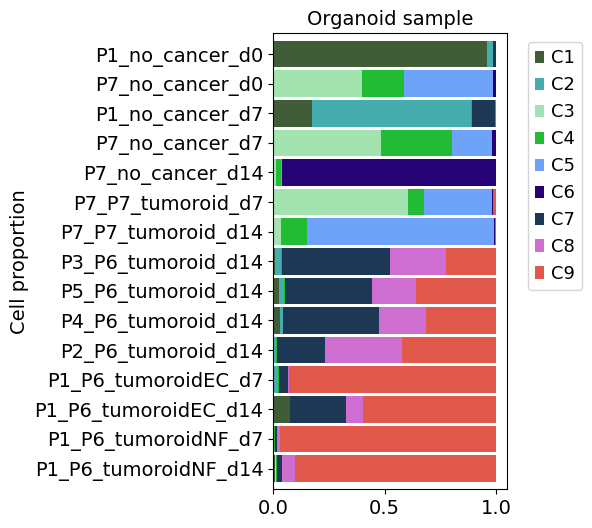

In [32]:


sample_order = ['P1_no_cancer_d0','P7_no_cancer_d0','P1_no_cancer_d7','P7_no_cancer_d7',
                'P7_no_cancer_d14',
                'P7_P7_tumoroid_d7','P7_P7_tumoroid_d14','P3_P6_tumoroid_d14',
                'P5_P6_tumoroid_d14', 'P4_P6_tumoroid_d14', 'P2_P6_tumoroid_d14',
                'P1_P6_tumoroidEC_d7', 'P1_P6_tumoroidEC_d14', 
                'P1_P6_tumoroidNF_d7','P1_P6_tumoroidNF_d14']


ct_forplot = adata_cancer.obs.groupby(['sample_id','leiden_m']).count()['celltype'].\
                    reset_index().set_index('sample_id').\
                    pivot(columns='leiden_m',values='celltype')
ct_forplot = ct_forplot.div(ct_forplot.sum(axis=1), axis=0).loc[sample_order[::-1]]

fig, axs = plt.subplots(1, 1, figsize=(8, 3), sharey=True)
ct_forplot.plot(kind='barh', stacked=True, figsize=(3, 6), width=0.9,
                color=[plate_level_all[col] for col in ct_forplot.columns],
                ax=axs)
axs.set_title("Organoid sample")
axs.set_ylabel("Cell proportion")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


fig.savefig(f'{fig_dir}/cancer_cell_proportion.pdf')


/tmp/ipykernel_2110935/1687821907.py:11: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(adata_cancer, markers4plot, groupby="leiden_m",


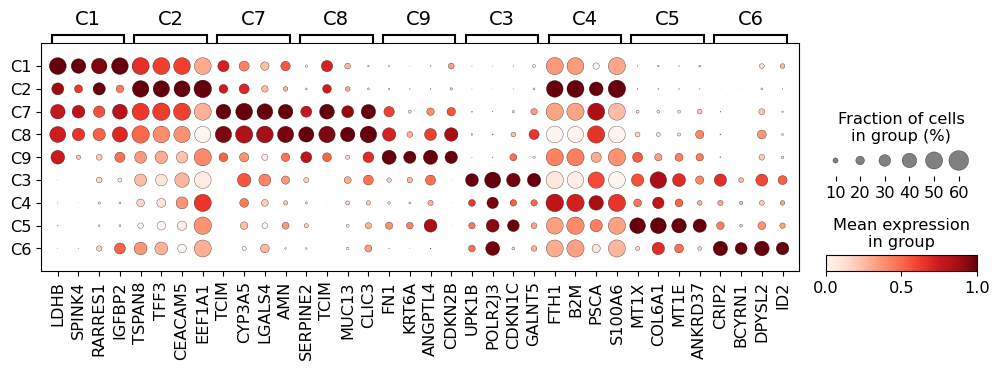

In [8]:
sc.tl.rank_genes_groups(adata_cancer, 'leiden_m', method='wilcoxon', key_added = "wilcoxon")

markers4plot={}
categories_order = ['C1','C2','C7','C8','C9','C3','C4','C5','C6']
for i in categories_order:
        df = sc.get.rank_genes_groups_df(adata_cancer, group=i, key='wilcoxon', 
                                        pval_cutoff=0.01, log2fc_min=0)
        markers4plot[i]=df.names.head(4).tolist()


sc.pl.dotplot(adata_cancer, markers4plot, groupby="leiden_m",
              categories_order=categories_order, 
#               cmap='coolwarm',
              standard_scale='var', 
              figsize=(12,3), save='cancer_feature_genes.pdf')


In [14]:
weighted_score_genes(adata_cancer, cancer_genes, cancer_weights, 'Cancer_score', use_raw=False)


/tmp/ipykernel_2110935/4172817815.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=adata_cancer.obs, x='leiden_m', y='Cancer_score', palette=plate_level_all, ax=ax)


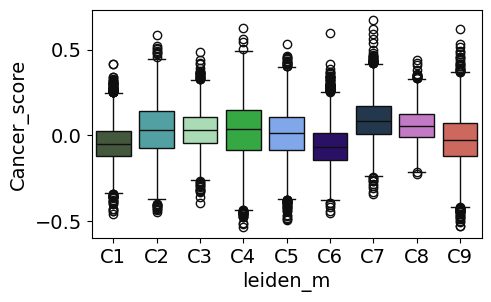

In [15]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
sns.boxplot(data=adata_cancer.obs, x='leiden_m', y='Cancer_score', palette=plate_level_all, ax=ax)
# ax.set_ylim(-.5, 0.7) 

fig.savefig(f'{fig_dir}/cancer_score_box.pdf')


In [36]:
adata_cancer.write_h5ad(f'{project_dir}/Ryo_Organoid/cancer_all_css_new.h5ad', compression="gzip")


In [16]:
from scipy.stats import mannwhitneyu
adata_obs=adata_cancer.obs

results = []
for cat in adata_obs.leiden_m.unique():
    group_other = adata_obs[adata_obs["leiden_m"] == cat]["Cancer_score"]
    stat, p_value = mannwhitneyu(adata_obs[adata_obs["leiden_m"].isin(['C1'])]["Cancer_score"], 
                                 group_other, alternative="less")
    results.append({"leiden_m": cat, "p_value": p_value, "stat": stat})

# Convert results to a DataFrame
results_df = pd.DataFrame(results)

results_df

,leiden_m,p_value,stat
0,C2,9.574659e-158,7793411.0
1,C7,0.000000e+00,8599275.0
2,C1,5.000008e-01,26491920.5
3,C8,0.000000e+00,5561138.0
4,C9,4.112970e-23,23918018.0
5,C4,3.088353e-139,8498766.0
6,C6,1.000000e+00,40317936.0
7,C5,8.694235e-142,17480628.0
8,C3,6.852368e-291,11912381.0


In [18]:
from scipy.stats import mannwhitneyu
adata_obs=adata_cancer.obs

results = []
for cat in adata_obs.leiden_m.unique():
    group_other = adata_obs[adata_obs["leiden_m"] == cat]["Cancer_score"]
    stat, p_value = mannwhitneyu(group_other, adata_obs[adata_obs["leiden_m"].isin(['C1'])]["Cancer_score"], 
                                 alternative="less")
    results.append({"leiden_m": cat, "p_value": p_value, "stat": stat})

# Convert results to a DataFrame
results_df = pd.DataFrame(results)

results_df

,leiden_m,p_value,stat
0,C2,1.000000e+00,15397483.0
1,C7,1.000000e+00,33968317.0
2,C1,5.000008e-01,26491920.5
3,C8,1.000000e+00,17651593.0
4,C9,1.000000e+00,28891127.0
5,C4,1.000000e+00,15871326.0
6,C6,2.509923e-25,33549356.0
7,C5,1.000000e+00,29163204.0
8,C3,1.000000e+00,26528018.0


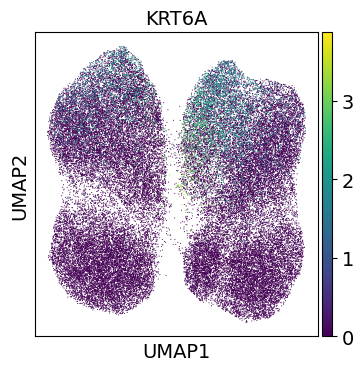

In [17]:
sc.pl.umap(adata_cancer, color='KRT6A')

### CAF

In [ ]:
adata_caf = adata[adata.obs.leiden.isin(['5','6','0'])]
adata_caf.obs['celltype'] = 'caf'

adata_caf = adata_caf.raw.to_adata()
sc.pp.highly_variable_genes(adata_caf, n_top_genes=2000, batch_key='sample_id')
adata_caf.raw = adata_caf
adata_caf = adata_caf[:, adata_caf.var['highly_variable']].copy()
sc.pp.scale(adata_caf, max_value=10)
sc.tl.pca(adata_caf)


In [ ]:
adata_caf = csspy.css(adata_caf, cor_method='spearman', resolution=2)
adata_caf = csspy.umap(adata_caf)
sc.tl.leiden(adata_caf, resolution=0.5)


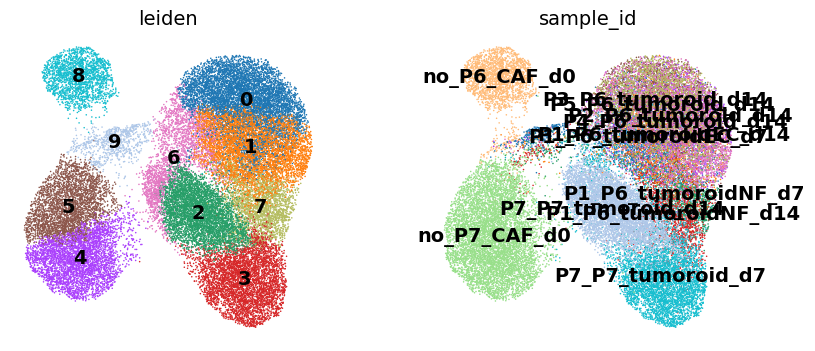

In [40]:
sc.pl.umap(adata_caf, color=['leiden', 'sample_id'], 
                      legend_loc='on data',
           color_map=gns, size=5, vmin=0.01, frameon=False)


In [41]:
adata_caf.obs['leiden_m'] = adata_caf.obs.leiden.map({
    '0':'C9',
    '1':'C8',
    '2':'C6',
    '3':'C7',
    '4':'C2',
    '5':'C2',
    '6':'C4',
    '7':'C5',
    '8':'C1',
    '9':'C3'
})

/tmp/ipykernel_257483/3526019465.py:1: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(adata_caf, color=['leiden', 'Timepoint','celltype', 'sample_id'],


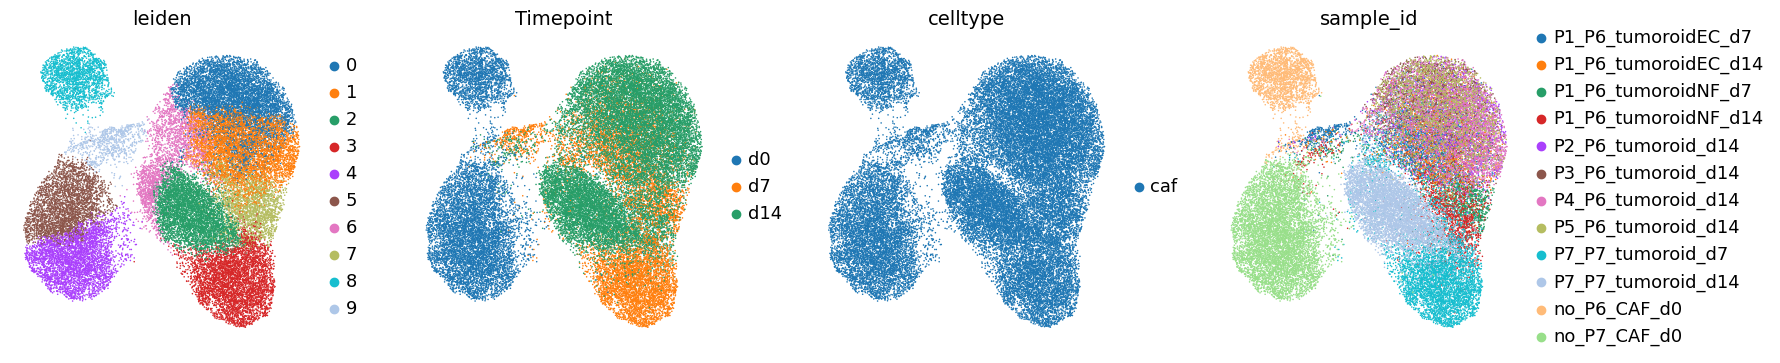

/tmp/ipykernel_257483/3526019465.py:4: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.umap(adata_caf, color=['leiden_m'],


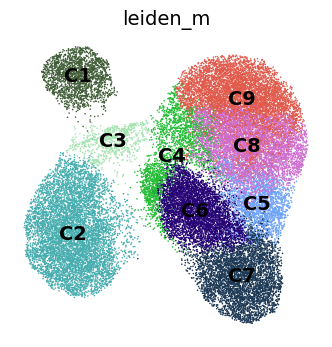

In [42]:

sc.pl.umap(adata_caf, color=['leiden', 'Timepoint','celltype', 'sample_id'], 
           color_map=gns, size=5, vmin=0.01, frameon=False, save='caf_meta.pdf')

sc.pl.umap(adata_caf, color=['leiden_m'], 
           palette=plate_level_all, 
           legend_loc='on data',
           color_map=gns, size=5, vmin=0.01, frameon=False,
          save='caf_leiden.pdf')



/tmp/ipykernel_257483/4229405205.py:8: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  ct_forplot = adata_caf.obs.groupby(['sample_id','leiden_m']).count()['celltype'].\


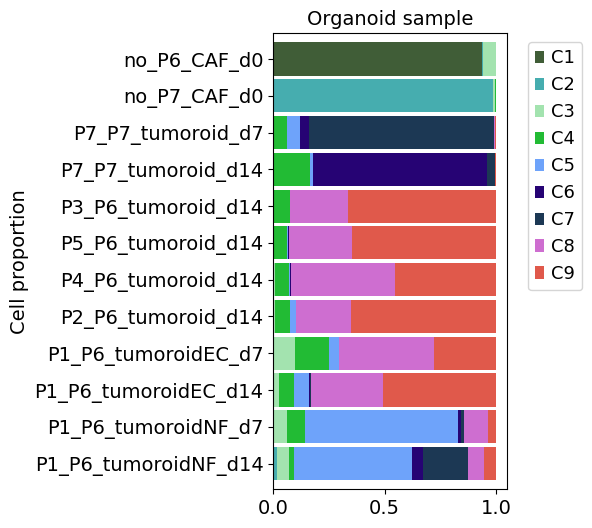

In [43]:


sample_order = ['no_P6_CAF_d0','no_P7_CAF_d0',
                'P7_P7_tumoroid_d7','P7_P7_tumoroid_d14','P3_P6_tumoroid_d14',
                'P5_P6_tumoroid_d14', 'P4_P6_tumoroid_d14', 'P2_P6_tumoroid_d14',
                'P1_P6_tumoroidEC_d7', 'P1_P6_tumoroidEC_d14', 
                'P1_P6_tumoroidNF_d7','P1_P6_tumoroidNF_d14']


ct_forplot = adata_caf.obs.groupby(['sample_id','leiden_m']).count()['celltype'].\
                    reset_index().set_index('sample_id').\
                    pivot(columns='leiden_m',values='celltype')
ct_forplot = ct_forplot.div(ct_forplot.sum(axis=1), axis=0).loc[sample_order[::-1]]

fig, axs = plt.subplots(1, 1, figsize=(8, 3), sharey=True)
ct_forplot.plot(kind='barh', stacked=True, figsize=(3, 6), width=0.9,
                color=[plate_level_all[col] for col in ct_forplot.columns],
                ax=axs)
axs.set_title("Organoid sample")
axs.set_ylabel("Cell proportion")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')


fig.savefig(f'{fig_dir}/caf_cell_proportion.pdf')


/tmp/ipykernel_257483/3492695294.py:11: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  sc.pl.dotplot(adata_caf, markers4plot, groupby="leiden_m",


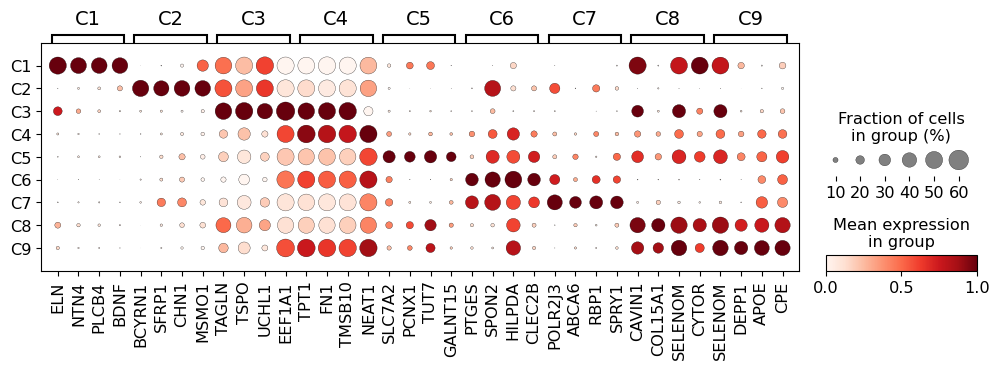

In [44]:
sc.tl.rank_genes_groups(adata_caf, 'leiden_m', method='wilcoxon', key_added = "wilcoxon")

markers4plot={}
categories_order = ['C1','C2','C3','C4','C5','C6','C7','C8','C9']
for i in categories_order:
        df = sc.get.rank_genes_groups_df(adata_caf, group=i, key='wilcoxon', 
                                        pval_cutoff=0.01, log2fc_min=0)
        markers4plot[i]=df.names.head(4).tolist()


sc.pl.dotplot(adata_caf, markers4plot, groupby="leiden_m",
              categories_order=categories_order, 
#               cmap='coolwarm',
              standard_scale='var', 
              figsize=(12,3), save='caf_feature_genes.pdf')


In [45]:
weighted_score_genes(adata_caf, caf_genes, caf_weights, 'CAF_score', use_raw=False)


/tmp/ipykernel_257483/3049404605.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=adata_caf.obs, x='leiden_m', y='CAF_score', palette=plate_level_all, ax=ax)


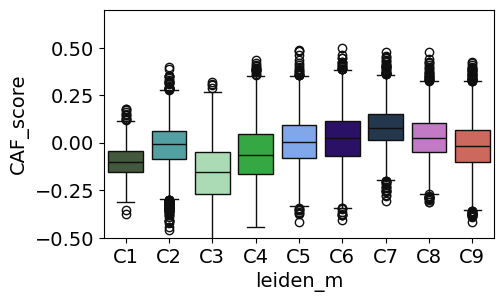

In [46]:
fig, ax = plt.subplots(1, 1, figsize=(5, 3))
sns.boxplot(data=adata_caf.obs, x='leiden_m', y='CAF_score', palette=plate_level_all, ax=ax)
ax.set_ylim(-.5, 0.7) 

fig.savefig(f'{fig_dir}/caf_score_box.pdf')


In [47]:
adata_caf.write_h5ad(f'{project_dir}/Ryo_Organoid/caf_all_css_new.h5ad', compression="gzip")


In [19]:
adata_caf = sc.read_h5ad(f'{project_dir}/Ryo_Organoid/caf_all_css_new.h5ad')


In [20]:
from scipy.stats import mannwhitneyu
adata_obs=adata_caf.obs

results = []
for cat in adata_obs.leiden_m.unique():
    group_other = adata_obs[adata_obs["leiden_m"] == cat]["CAF_score"]
    stat, p_value = mannwhitneyu(adata_obs[adata_obs["leiden_m"].isin(['C1','C2'])]["CAF_score"], 
                                 group_other, alternative="less")
    results.append({"leiden_m": cat, "p_value": p_value, "stat": stat})

# Convert results to a DataFrame
results_df = pd.DataFrame(results)

results_df

,leiden_m,p_value,stat
0,C1,1.000000e+00,12234585.5
1,C3,1.000000e+00,5005860.0
2,C2,7.187628e-32,27628935.0
3,C8,3.142842e-188,15805155.0
4,C9,7.912222e-15,27285268.0
5,C4,1.000000e+00,12469223.0
6,C5,8.590369e-43,8668206.0
7,C7,0.000000e+00,9094813.0
8,C6,1.679566e-123,15486569.0


In [21]:
from scipy.stats import mannwhitneyu
adata_obs=adata_caf.obs

results = []
for cat in adata_obs.leiden_m.unique():
    group_other = adata_obs[adata_obs["leiden_m"] == cat]["CAF_score"]
    stat, p_value = mannwhitneyu(group_other, adata_obs[adata_obs["leiden_m"].isin(['C1','C2'])]["CAF_score"], 
                                 alternative="less")
    results.append({"leiden_m": cat, "p_value": p_value, "stat": stat})

# Convert results to a DataFrame
results_df = pd.DataFrame(results)

results_df

,leiden_m,p_value,stat
0,C1,8.683819e-153,5543053.5
1,C3,2.677548e-101,1833754.0
2,C2,1.000000e+00,34320467.0
3,C8,1.000000e+00,29188076.0
4,C9,1.000000e+00,31521126.0
5,C4,1.482821e-21,9719342.0
6,C5,1.000000e+00,12529240.0
7,C7,1.000000e+00,30808888.0
8,C6,1.000000e+00,25658263.0
